In [4]:
from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple, Union
import re

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [14]:
@dataclass(frozen=True)
class MjoHovPlotConfig:
    period: str = "2012-2013"
    time_dim: str = "time"          # integer index 0..N-1
    lon_dim: str = "lon"
    time_str_coords: Sequence[str] = field(
        default_factory=lambda: (
            "time_str_ref_olr",
            "time_str_model_flut",
            "time_str_model_prect",
            "time_str_olr",
            "time_str_prect",
            "time_str",
        )
    )

    # variables inside per-exp files
    v_ref_olr: str = "hov_ref_olr"
    v_model_olr: str = "hov_model_flut"
    v_model_p: str = "hov_model_prect"

    # variables inside TRUTH file
    v_truth_olr: str = "hov_ref_olr"
    v_truth_p: str = "hov_ref_prect"

    # metadata for titles (optional)
    lat_band: Tuple[float, float] = (-10.0, 10.0)
    lon_sector: Tuple[float, float] = (0.0, 360.0)

    # plotting
    figsize_one: Tuple[float, float] = (8.0, 12.0)
    figsize_grid: Tuple[float, float] = (8.0, 12.0)
    cmap: str = "RdBu_r"
    robust: bool = True
    robust_q: Tuple[float, float] = (2.0, 98.0)
    add_zero_lon: bool = False

    max_xticks: int = 9
    max_yticks: int = 8
    
    ref_start_date: str = "2012-01-01"

    def lat_band_str(self) -> str:
        a, b = self.lat_band
        if a < 0 < b:
            return f"{abs(a):g}°S–{abs(b):g}°N"
        return f"{a:g}–{b:g}°"

    def lon_sector_str(self) -> str:
        a, b = self.lon_sector
        return f"{a:g}–{b:g}°E"


class MjoHovPlotter:
    """
    Plot Hovmöller diagnostics produced by your MJOMetrics pipeline.
    """

    def __init__(self, hov_dir: Union[str, Path], cfg: Optional[MjoHovPlotConfig] = None):
        self.hov_dir = Path(hov_dir)
        self.cfg = cfg or MjoHovPlotConfig()

    # -------------------------
    # IO helpers
    # -------------------------
    def _open(self, path: Path) -> xr.Dataset:
        return xr.open_dataset(path)

    def _pick_time_str_coord(self, da: xr.DataArray) -> Optional[str]:
        for c in self.cfg.time_str_coords:
            if c in da.coords:
                return c
        return None

    def _time_tick_labels(self, da: xr.DataArray) -> Tuple[np.ndarray, List[str]]:
        """
        Use integer time index as days since initialization.
        """
        tdim = self.cfg.time_dim
        n = da.sizes[tdim]
    
        nt = min(self.cfg.max_yticks, n)
        idx = np.linspace(0, n - 1, nt).astype(int)
    
        # labels are simply days since init
        labs = [f"{i}" for i in idx]
        return idx, labs

    def _lon_tick_labels(self, da: xr.DataArray) -> Tuple[np.ndarray, List[str]]:
        ldim = self.cfg.lon_dim
        lon = da[ldim].values
        n = lon.size
        nt = min(self.cfg.max_xticks, n)
        idx = np.linspace(0, n - 1, nt).astype(int)
        labs = [f"{lon[i]:.0f}" for i in idx]
        return idx, labs

    def _robust_limits(self, *das: xr.DataArray) -> Tuple[float, float]:
        vals = []
        for da in das:
            v = da.values
            v = v[np.isfinite(v)]
            if v.size:
                vals.append(v)
        if not vals:
            return -1.0, 1.0

        allv = np.concatenate(vals)
        if self.cfg.robust:
            q0, q1 = self.cfg.robust_q
            vmin = np.percentile(allv, q0)
            vmax = np.percentile(allv, q1)
        else:
            vmin = float(np.min(allv))
            vmax = float(np.max(allv))

        m = max(abs(vmin), abs(vmax))
        return -m, m

    # -------------------------
    # NEW: time windowing helpers
    # -------------------------
    def _slice_time_by_index(
        self,
        da: xr.DataArray,
        *,
        t0: Optional[int] = None,
        t1: Optional[int] = None,
    ) -> xr.DataArray:
        if t0 is None and t1 is None:
            return da
        sl = slice(t0, t1)
        return da.isel({self.cfg.time_dim: sl})

    def _slice_time_by_datestr(
        self,
        da: xr.DataArray,
        *,
        date0: Optional[str] = None,
        date1: Optional[str] = None,
    ) -> xr.DataArray:
        """
        Slice using the available time_str_* coordinate (YYYY-MM-DD or YYYY-MM-DD HH:MM:SS...).
        date1 is exclusive (like pandas/xarray slicing conventions).
        """
        if date0 is None and date1 is None:
            return da

        c = self._pick_time_str_coord(da)
        if c is None:
            raise ValueError("No time_str_* coordinate found; use t0/t1 index slicing instead.")

        # Convert time_str to comparable YYYY-MM-DD strings
        ts = np.array([str(s).split(" ")[0] for s in da[c].values], dtype=object)

        mask = np.ones(ts.shape, dtype=bool)
        if date0 is not None:
            mask &= (ts >= date0)
        if date1 is not None:
            mask &= (ts < date1)

        idx = np.where(mask)[0]
        if idx.size == 0:
            raise ValueError(f"No time steps found in requested window: date0={date0}, date1={date1}")

        i0 = int(idx[0])
        i1 = int(idx[-1]) + 1
        return da.isel({self.cfg.time_dim: slice(i0, i1)})

    def _apply_time_window(
        self,
        da: xr.DataArray,
        *,
        t0: Optional[int] = None,
        t1: Optional[int] = None,
        date0: Optional[str] = None,
        date1: Optional[str] = None,
    ) -> xr.DataArray:
        # If both provided, index wins (explicit and unambiguous)
        if t0 is not None or t1 is not None:
            return self._slice_time_by_index(da, t0=t0, t1=t1)
        return self._slice_time_by_datestr(da, date0=date0, date1=date1)

    def _window_label(
        self,
        *,
        t0: Optional[int] = None,
        t1: Optional[int] = None,
        date0: Optional[str] = None,
        date1: Optional[str] = None,
    ) -> str:
        if t0 is not None or t1 is not None:
            a = 0 if t0 is None else t0
            b = "" if t1 is None else t1
            return f"t[{a}:{b}]"
        if date0 is None and date1 is None:
            return "full"
        a = "" if date0 is None else date0
        b = "" if date1 is None else date1
        return f"{a}–{b}".strip("–")

    # -------------------------
    # Skill metrics
    # -------------------------
    @staticmethod
    def _rmse(a: xr.DataArray, b: xr.DataArray) -> float:
        d = (a - b).values
        d = d[np.isfinite(d)]
        return float(np.sqrt(np.mean(d * d))) if d.size else np.nan

    @staticmethod
    def _corr(a: xr.DataArray, b: xr.DataArray) -> float:
        av = a.values.ravel()
        bv = b.values.ravel()
        m = np.isfinite(av) & np.isfinite(bv)
        if m.sum() < 10:
            return np.nan
        av = av[m]
        bv = bv[m]
        av = av - av.mean()
        bv = bv - bv.mean()
        denom = (np.sqrt((av * av).mean()) * np.sqrt((bv * bv).mean()))
        return float((av * bv).mean() / denom) if denom > 0 else np.nan

    # -------------------------
    # Public API
    # -------------------------
    def truth_path(self) -> Path:
        return self.hov_dir / f"mjo_hov_TRUTH_{self.cfg.period}.nc"

    def exp_path(self, exp: str) -> Path:
        return self.hov_dir / f"mjo_hov_{exp}_{self.cfg.period}.nc"

    def list_experiments(self) -> List[str]:
        pats = sorted(self.hov_dir.glob(f"mjo_hov_*_{self.cfg.period}.nc"))
        out: List[str] = []
        rgx = re.compile(rf"^mjo_hov_(?P<exp>.+)_{re.escape(self.cfg.period)}\.nc$")
        for p in pats:
            if "TRUTH" in p.name:
                continue
            m = rgx.match(p.name)
            if m:
                out.append(m.group("exp"))
        return out

    def load_truth(self) -> xr.Dataset:
        p = self.truth_path()
        if not p.exists():
            raise FileNotFoundError(str(p))
        return self._open(p)

    def load_exp(self, exp: str) -> xr.Dataset:
        p = self.exp_path(exp)
        if not p.exists():
            raise FileNotFoundError(str(p))
        return self._open(p)

    # -------------------------
    # Plot: overlay for one experiment
    # -------------------------
    def plot_one_experiment(
        self,
        exp: str,
        *,
        t0: Optional[int] = None,
        t1: Optional[int] = None,
        date0: Optional[str] = None,
        date1: Optional[str] = None,
        out_png: Optional[Union[str, Path]] = None,
        show: bool = True,
    ) -> plt.Figure:
        ds_t = self.load_truth()
        ds_e = self.load_exp(exp)

        truth_olr = self._apply_time_window(ds_t[self.cfg.v_truth_olr], t0=t0, t1=t1, date0=date0, date1=date1)
        truth_p   = self._apply_time_window(ds_t[self.cfg.v_truth_p],   t0=t0, t1=t1, date0=date0, date1=date1)
        model_olr = self._apply_time_window(ds_e[self.cfg.v_model_olr], t0=t0, t1=t1, date0=date0, date1=date1)
        model_p   = self._apply_time_window(ds_e[self.cfg.v_model_p],   t0=t0, t1=t1, date0=date0, date1=date1)

        vmin_olr, vmax_olr = self._robust_limits(truth_olr, model_olr)
        vmin_p,   vmax_p   = self._robust_limits(truth_p,   model_p)

        fig, axs = plt.subplots(2, 2, figsize=self.cfg.figsize_one, constrained_layout=True)

        def draw(ax, da, title, vmin, vmax):
            im = ax.pcolormesh(
                da[self.cfg.lon_dim].values,
                da[self.cfg.time_dim].values,
                da.values,
                shading="auto",
                cmap=self.cfg.cmap,
                vmin=vmin,
                vmax=vmax,
            )
            ax.set_title(title)
            ax.set_xlabel("Longitude")
            ax.set_ylabel(f"Days since {self.cfg.ref_start_date}")

            xt, xl = self._lon_tick_labels(da)
            ax.set_xticks(da[self.cfg.lon_dim].values[xt])
            ax.set_xticklabels(xl, rotation=0)

            yt, yl = self._time_tick_labels(da)
            ax.set_yticks(da[self.cfg.time_dim].values[yt])
            ax.set_yticklabels(yl)

            if self.cfg.add_zero_lon:
                lons = da[self.cfg.lon_dim].values
                if np.nanmin(lons) <= 0.0 <= np.nanmax(lons):
                    ax.axvline(0.0, lw=1)
            return im

        im00 = draw(axs[0, 0], truth_olr, "TRUTH OLR (FLUT)", vmin_olr, vmax_olr)
        draw(axs[0, 1], model_olr, f"{exp} OLR (FLUT)", vmin_olr, vmax_olr)
        im10 = draw(axs[1, 0], truth_p,   "TRUTH PRECT", vmin_p, vmax_p)
        draw(axs[1, 1], model_p,   f"{exp} PRECT", vmin_p, vmax_p)

        cb0 = fig.colorbar(im00, ax=axs[0, :].ravel().tolist(), orientation="vertical", shrink=0.85)
        cb0.set_label("Standardized anomaly")
        cb1 = fig.colorbar(im10, ax=axs[1, :].ravel().tolist(), orientation="vertical", shrink=0.85)
        cb1.set_label("Standardized anomaly")

        c_olr = self._corr(model_olr, truth_olr)
        r_olr = self._rmse(model_olr, truth_olr)
        c_p = self._corr(model_p, truth_p)
        r_p = self._rmse(model_p, truth_p)

        wlab = self._window_label(t0=t0, t1=t1, date0=date0, date1=date1)
        fig.suptitle(
            f"MJO Hovmöller comparison ({self.cfg.period}; {wlab})\n"
            f"{exp}: OLR corr={c_olr:.2f}, rmse={r_olr:.2f} | PRECT corr={c_p:.2f}, rmse={r_p:.2f}",
            y=1.02,
            fontsize=14,
        )

        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=200, bbox_inches="tight")

        if show:
            plt.show()
        return fig

    # -------------------------
    # Plot: grid across experiments (OLR or PRECT)
    # -------------------------
    def plot_grid(
        self,
        *,
        var: str = "olr",
        exps: Optional[Sequence[str]] = None,
        ncols: int = 3,
        t0: Optional[int] = None,
        t1: Optional[int] = None,
        date0: Optional[str] = None,
        date1: Optional[str] = None,
        out_png: Optional[Union[str, Path]] = None,
        show: bool = True,
    ) -> plt.Figure:
        if exps is None:
            exps = self.list_experiments()

        ds_t = self.load_truth()
        truth_full = ds_t[self.cfg.v_truth_olr] if var.lower() == "olr" else ds_t[self.cfg.v_truth_p]
        truth = self._apply_time_window(truth_full, t0=t0, t1=t1, date0=date0, date1=date1)

        models = []
        for e in exps:
            ds_e = self.load_exp(e)
            da_full = ds_e[self.cfg.v_model_olr] if var.lower() == "olr" else ds_e[self.cfg.v_model_p]
            da = self._apply_time_window(da_full, t0=t0, t1=t1, date0=date0, date1=date1)
            models.append((e, da))

        vmin, vmax = self._robust_limits(truth, *(da for _, da in models))

        n = len(exps) + 1
        nrows = int(np.ceil(n / ncols))
        
        fig, axs = plt.subplots(nrows, ncols, figsize=self.cfg.figsize_grid, constrained_layout=True)
        axs = np.atleast_1d(axs).ravel()

        def draw(ax, da, title):
            im = ax.pcolormesh(
                da[self.cfg.lon_dim].values,
                da[self.cfg.time_dim].values,
                da.values,
                shading="auto",
                cmap=self.cfg.cmap,
                vmin=vmin,
                vmax=vmax,
            )
            ax.set_title(title, fontsize=11)

            xt, xl = self._lon_tick_labels(da)
            ax.set_xticks(da[self.cfg.lon_dim].values[xt])
            ax.set_xticklabels(xl, rotation=0, fontsize=9)

            yt, yl = self._time_tick_labels(da)
            ax.set_yticks(da[self.cfg.time_dim].values[yt])
            ax.set_yticklabels(yl, fontsize=9)
            return im

        im0 = draw(axs[0], truth, "TRUTH")
        for i, (e, da) in enumerate(models, start=1):
            c = self._corr(da, truth)
            r = self._rmse(da, truth)
            draw(axs[i], da, f"{e}\n(corr={c:.2f}, rmse={r:.2f})")

        for j in range(n, len(axs)):
            axs[j].axis("off")

        wlab = self._window_label(t0=t0, t1=t1, date0=date0, date1=date1)
        fig.suptitle(
            f"MJO Hovmöller grid ({self.cfg.period}; {wlab}) - {var.upper()} | "
            f"{self.cfg.lat_band_str()} | {self.cfg.lon_sector_str()}",
            y=1.02,
            fontsize=14,
        )

        cb = fig.colorbar(im0, ax=axs[:n].tolist(), orientation="vertical", shrink=0.85)
        cb.set_label("Standardized anomaly")

        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=200, bbox_inches="tight")

        if show:
            plt.show()
        return fig


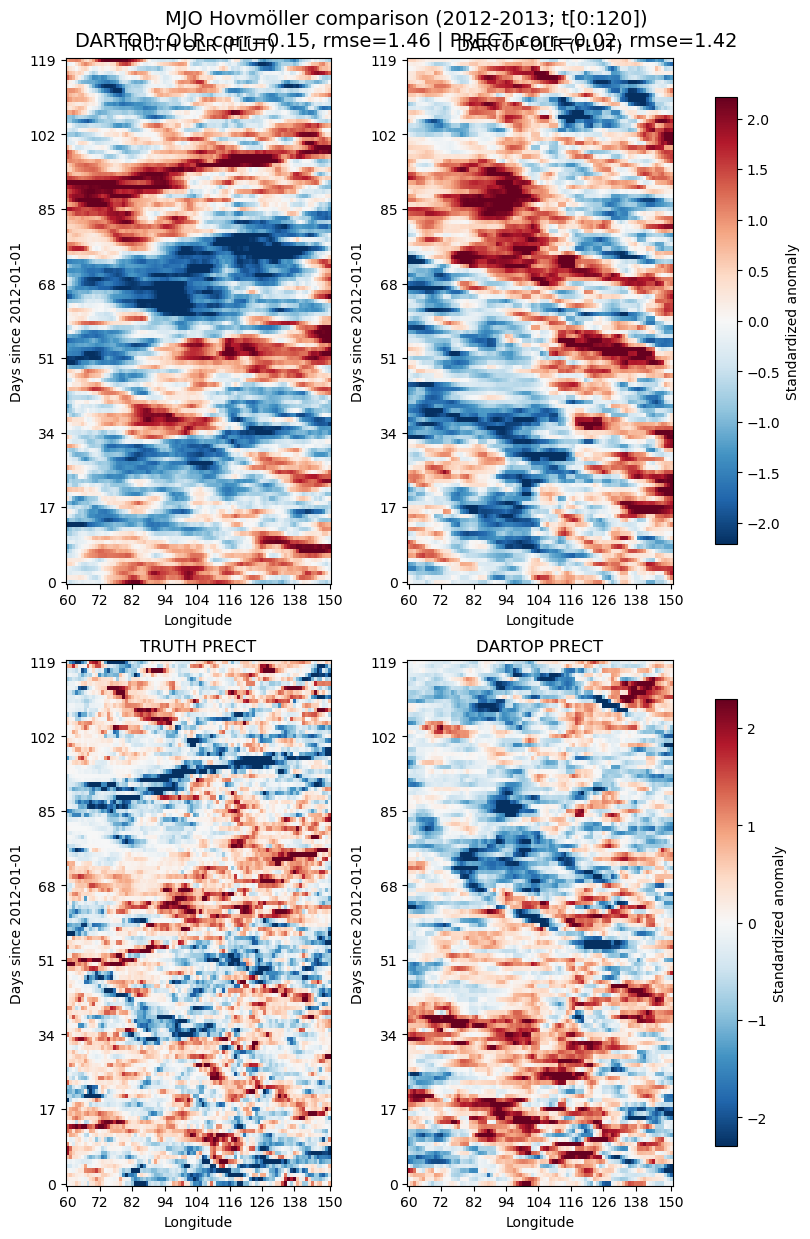

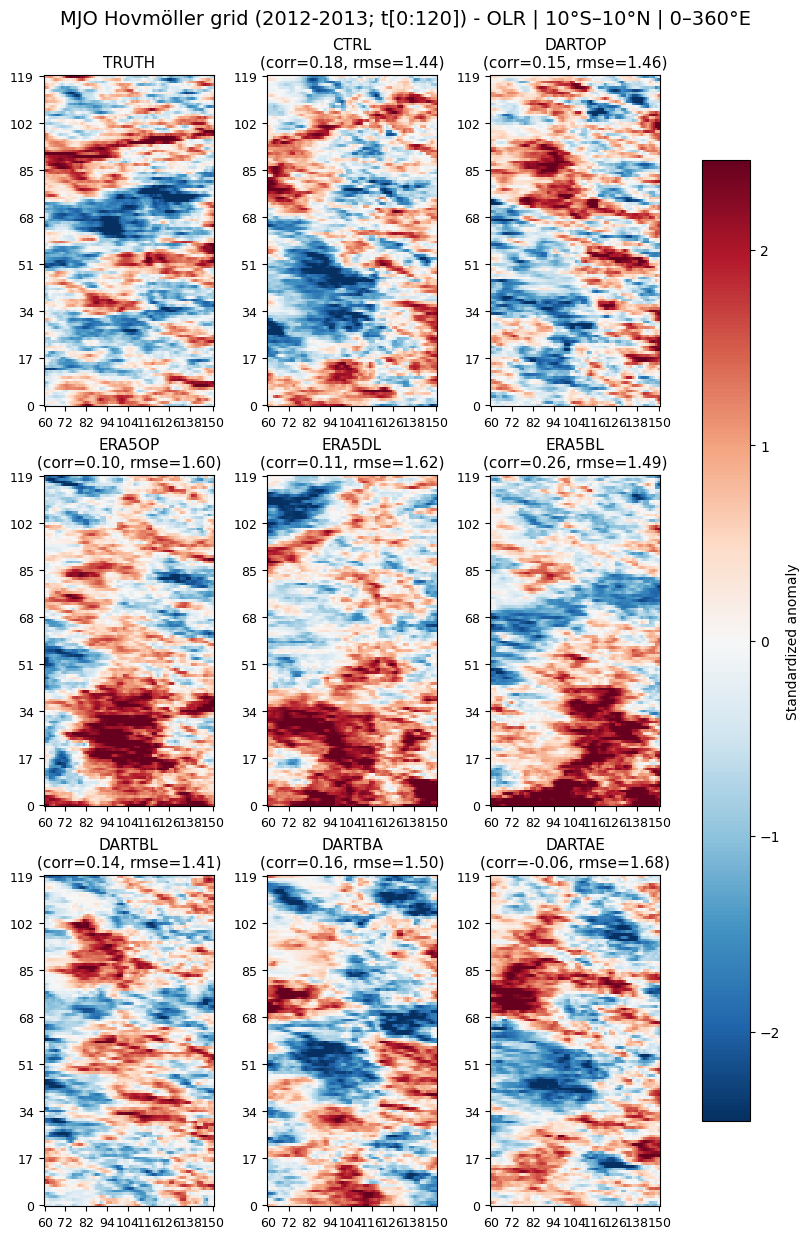

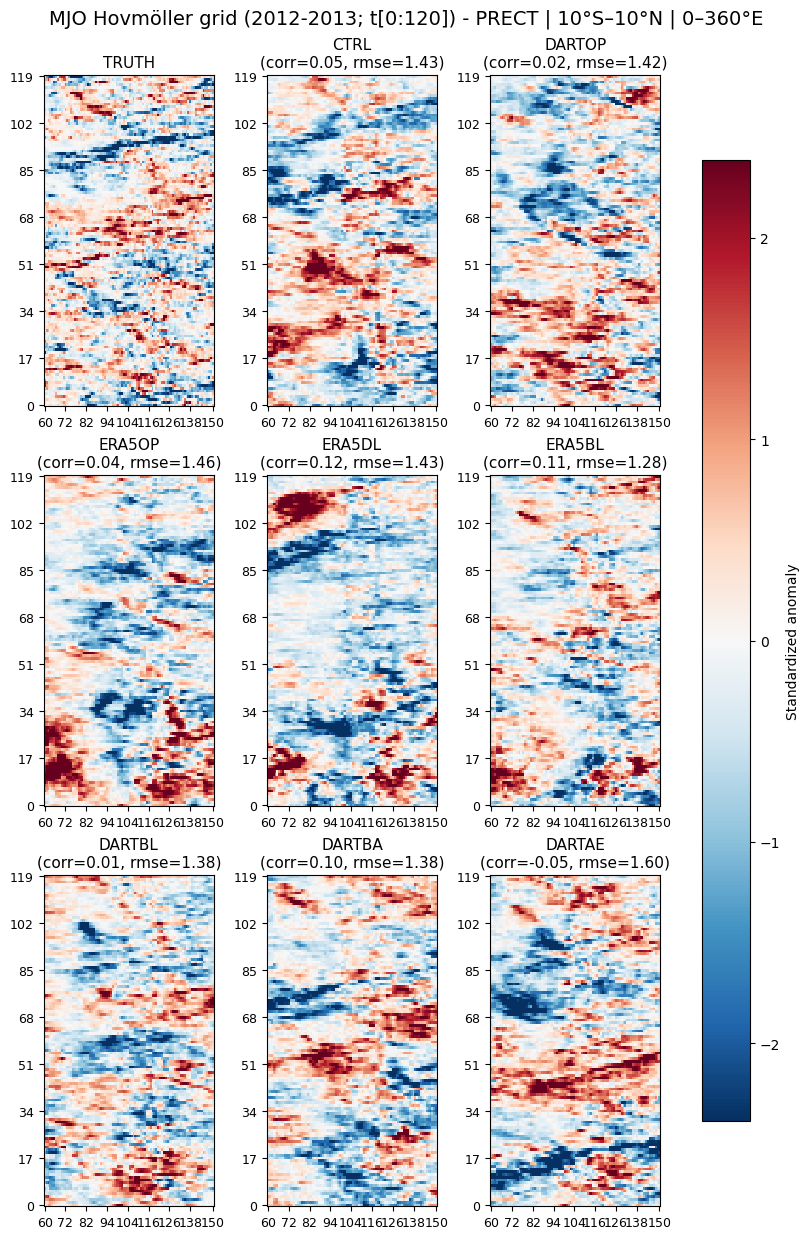

In [15]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    hov_dir = Path(work_dir) / "figure_data" / "mjo"
    fig_dir = Path("./")
    fig_dir.mkdir(parents=True, exist_ok=True)

    exp_list = ["CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE"]

    cfg = MjoHovPlotConfig(
        period="2012-2013",
        lat_band=(-10.0, 10.0),
        lon_sector=(0.0, 360.0),
        add_zero_lon=False,
    )

    plotter = MjoHovPlotter(hov_dir=hov_dir, cfg=cfg)

    # choose window by index: [0, 120)
    t0, t1 = 0, 120

    # (A) One experiment: TRUTH vs EXP (OLR + PRECT)
    plotter.plot_one_experiment(
        "DARTOP",
        t0=t0, t1=t1,
        out_png=fig_dir / "fig_mjo_hov_one_DARTOP_2012-2013_t0-120.png",
        show=True,
    )

    # (B) Grid across experiments (OLR)
    plotter.plot_grid(
        var="olr",
        exps=exp_list,
        ncols=3,
        t0=t0, t1=t1,
        out_png=fig_dir / "fig_mjo_hov_grid_OLR_2012-2013_t0-120.png",
        show=True,
    )

    # (C) Grid across experiments (PRECT)
    plotter.plot_grid(
        var="prect",
        exps=exp_list,
        ncols=3,
        t0=t0, t1=t1,
        out_png=fig_dir / "fig_mjo_hov_grid_PRECT_2012-2013_t0-120.png",
        show=True,
    )
